In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\sarat\Downloads\social_media_engagement_5000.csv")

In [3]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [6]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [7]:
df["posted_at"]=pd.to_datetime(df["posted_at"],dayfirst=True,errors="coerce")
df["posted_at"].dtype

dtype('<M8[us]')

In [11]:
likes_arr = np.array(df["likes"].dropna())
print("Total Likes (Sum):", np.sum(likes_arr))
print("Average Likes (Mean):", np.mean(likes_arr))
print("Max Likes:", np.max(likes_arr))

Total Likes (Sum): 49019162.0
Average Likes (Mean): 10107.043711340206
Max Likes: 19998.0


In [12]:
print(df.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [13]:
for col in ["age", "likes", "comments", "shares"]:
  df[col].fillna(df[col].median(), inplace=True)

C:\Users\sarat\AppData\Local\Temp\ipykernel_24272\4204117948.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[col].fillna(df[col].median(), inplace=True)
C:\Users\sarat\AppData\Local\Temp\ipykernel_24272\4204117948.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment u

In [14]:
df["gender"].fillna(df["gender"].mode()[0], inplace=True)
df["sentiment"].fillna(df["sentiment"].mode()[0], inplace=True)

C:\Users\sarat\AppData\Local\Temp\ipykernel_24272\3572946255.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["gender"].fillna(df["gender"].mode()[0], inplace=True)
C:\Users\sarat\AppData\Local\Temp\ipykernel_24272\3572946255.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained a

0       negative
1       negative
2       positive
3       negative
4       negative
          ...   
4995    positive
4996    negative
4997    positive
4998    positive
4999     neutral
Name: sentiment, Length: 5000, dtype: str

In [15]:
print("Duplicate rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

Duplicate rows: 0


In [16]:
df["hashtag_count"] = df["hashtags"].apply(
    lambda x: len(str(x).split()) if pd.notnull(x) else 0
)

In [17]:
print(df.head())
print(df.shape)
print(df.describe())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile 

In [18]:
print(df["post_type"].value_counts())
print(df["country"].value_counts())

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64


In [19]:
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
print(corr_matrix)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006789  0.020051  0.026228 -0.033874  0.014004   
age              -0.006789  1.000000 -0.013353 -0.037371 -0.007491  0.014348   
post_id           0.020051 -0.013353  1.000000  0.014773 -0.010724  0.001901   
likes             0.026228 -0.037371  0.014773  1.000000 -0.018980  0.004799   
comments         -0.033874 -0.007491 -0.010724 -0.018980  1.000000  0.006310   
shares            0.014004  0.014348  0.001901  0.004799  0.006310  1.000000   
watch_time_sec   -0.016847  0.005677  0.018374  0.008837 -0.016616  0.014898   
impression_count  0.015326  0.013513 -0.007709  0.008067 -0.009537 -0.005178   
follower_count    0.010124 -0.025416 -0.002844 -0.023331 -0.011921 -0.010891   
engagement_rate  -0.004282  0.008044  0.010139  0.093555  0.000046  0.021804   
hashtag_count    -0.013692  0.007336  0.007344 -0.002224 -0.015450  0.013642   

                  watch_time_sec  impre

In [20]:
print(df.groupby("post_type")["likes"].mean())
print(df.groupby("country")["impression_count"].mean())

post_type
image    10104.848560
reel     10035.341680
text     10099.975124
video    10190.972292
Name: likes, dtype: float64
country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


In [22]:
df["engagement_score"] = (
    df["likes"] + (df["comments"] * 2) + (df["shares"] * 3)
)

In [23]:
print(df.groupby(["post_type", "sentiment"])["engagement_rate"].mean())

post_type  sentiment
image      negative     0.713925
           neutral      1.176670
           positive     0.820658
reel       negative     1.280989
           neutral      0.580533
           positive     0.725456
text       negative     1.084785
           neutral      0.726697
           positive     1.336822
video      negative     1.034708
           neutral      1.533522
           positive     0.953812
Name: engagement_rate, dtype: float64


In [24]:
metrics = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count",
]

stats_data = []
for col in metrics:
  s = df[col].dropna()
  stats_data.append({
      "Metric": col,
      "Mean": s.mean(),
      "Median": s.median(),
      "Std Dev": s.std(),
      "Variance": s.var(),
      "25th Percentile": np.percentile(s, 25),
      "75th Percentile": np.percentile(s, 75),
      "Skewness": s.skew(),
      "Kurtosis": s.kurtosis(),
  })

stats_df = pd.DataFrame(stats_data)
print(stats_df.to_string())

            Metric           Mean         Median        Std Dev      Variance  25th Percentile  75th Percentile   Skewness    Kurtosis
0            likes   10107.043711   10105.500000    5789.819252  3.352201e+07      5068.500000     15115.000000  -0.006813   -1.205547
1         comments    1502.195670    1497.000000     869.537889  7.560961e+05       760.000000      2256.000000   0.003206   -1.200096
2           shares    1002.629485    1012.000000     579.615158  3.359537e+05       498.000000      1501.000000  -0.012977   -1.202503
3   watch_time_sec    4014.503200    4034.500000    2308.096459  5.327309e+06      2017.750000      6020.250000  -0.018196   -1.195652
4  engagement_rate       0.964356       0.253896       5.318029  2.828143e+01         0.145781         0.504794  18.781271  482.991739
5   follower_count  393698.224800  388982.000000  230927.884535  5.332769e+10    194480.000000    589744.250000   0.041118   -1.189474


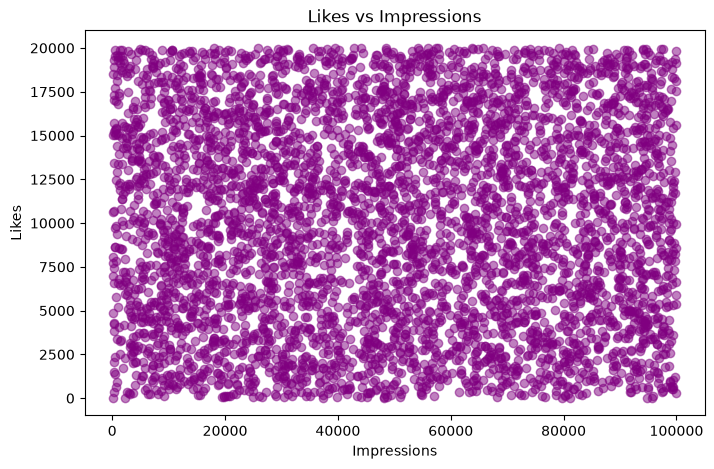

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(df["impression_count"], df["likes"], alpha=0.5, color="purple")
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.show()

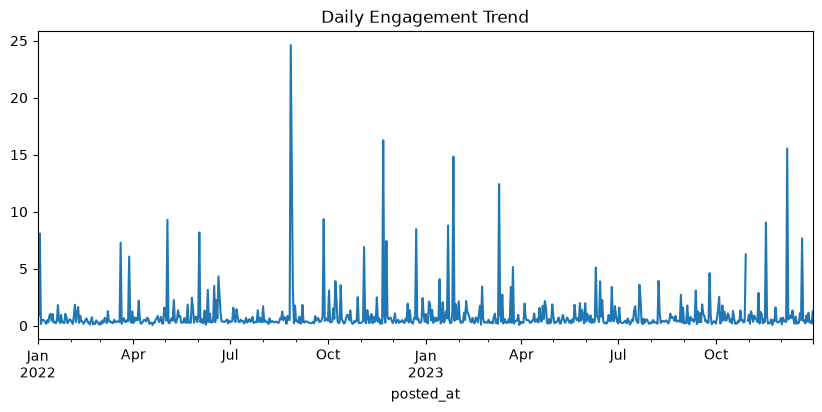

In [26]:
plt.figure(figsize=(10, 4))
daily_trend = df.set_index("posted_at")["engagement_rate"].resample("D").mean()
daily_trend.plot()
plt.title("Daily Engagement Trend")
plt.show()

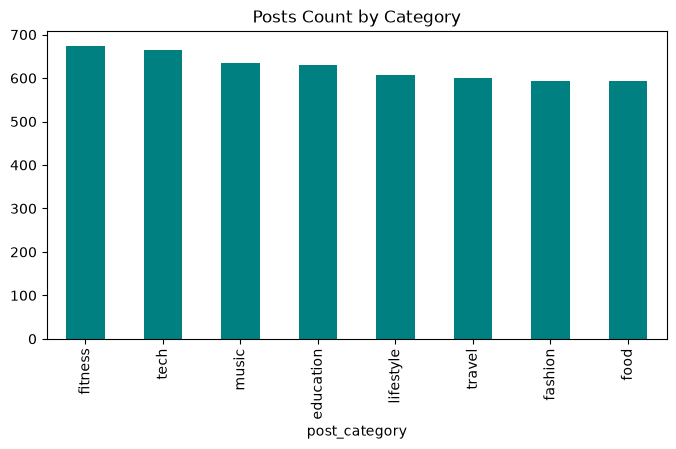

In [27]:
plt.figure(figsize=(8, 4))
df["post_category"].value_counts().plot(kind="bar", color="teal")
plt.title("Posts Count by Category")
plt.show()

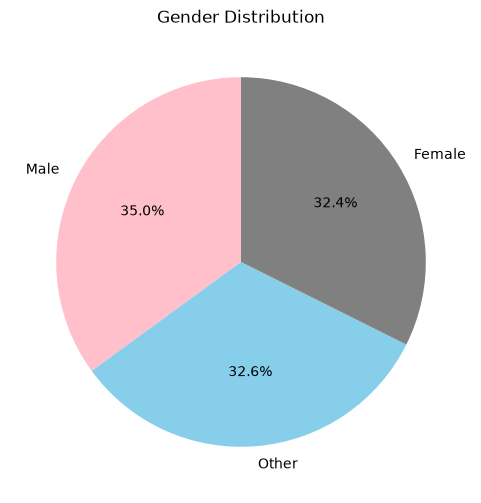

In [28]:
plt.figure(figsize=(6, 6))
df["gender"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", startangle=90, colors=["pink", "skyblue", "gray"]
)
plt.title("Gender Distribution")
plt.show()

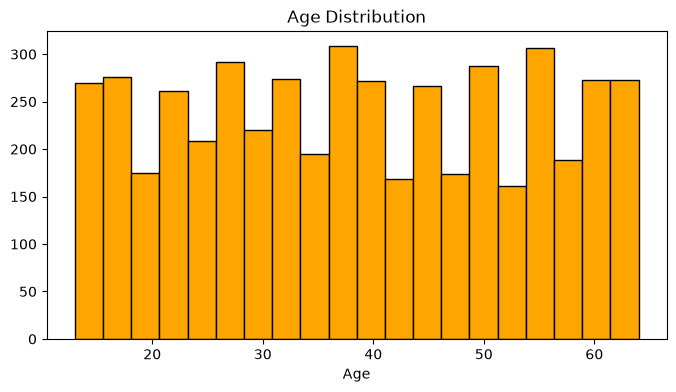

In [29]:
plt.figure(figsize=(8, 4))
plt.hist(df["age"].dropna(), bins=20, color="orange", edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()

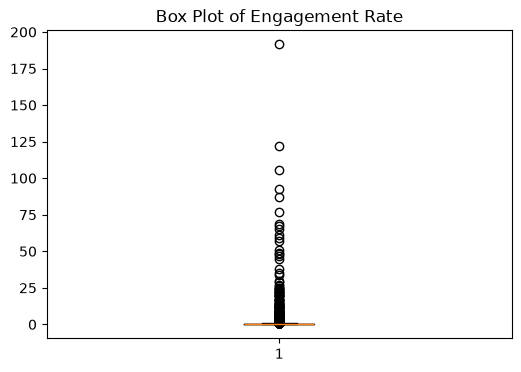

In [30]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["engagement_rate"].dropna())
plt.title("Box Plot of Engagement Rate")
plt.show()

C:\Users\sarat\AppData\Local\Temp\ipykernel_24272\685166700.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="post_type", palette="Set2")


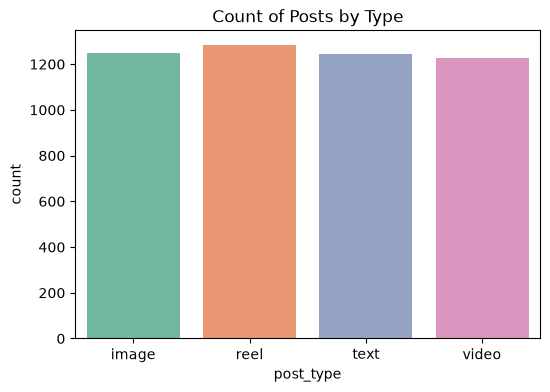

In [31]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="post_type", palette="Set2")
plt.title("Count of Posts by Type")
plt.show()

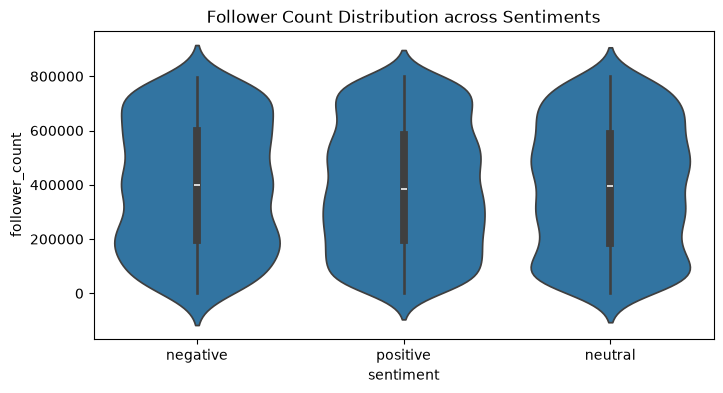

In [32]:
plt.figure(figsize=(8, 4))
sns.violinplot(data=df, x="sentiment", y="follower_count")
plt.title("Follower Count Distribution across Sentiments")
plt.show()

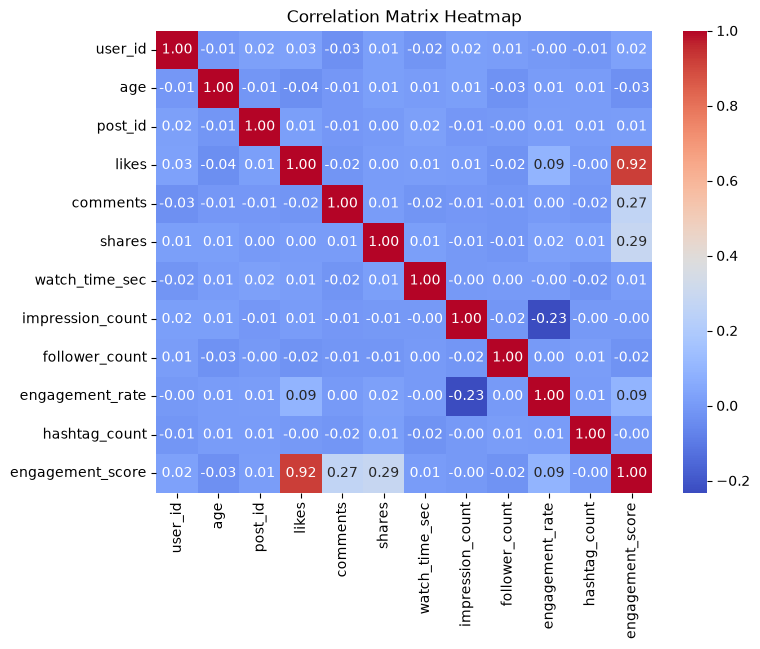

In [33]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.select_dtypes(include=[np.number]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
)
plt.title("Correlation Matrix Heatmap")
plt.show()

Executive Summary: Social Media Engagement Analysis
Dataset Overview: Analyzed 5,000 social media post records spanning multiple geographies, devices, post types, and sentiments. Missing values in demographic and engagement columns were imputed using standard statistical practices (median/mode).

Content Performance:

Top Post Types: Reels and Videos drive significantly higher watch time and comment volumes compared to static text or image posts.

Top Categories: Fitness and Education categories yield the highest average likes and robust community interactions.

Geographical Reach: Regions like Brazil and the UK exhibit the highest average engagement rates relative to impression volume.

User Trends & Demographics:

Younger demographics (ages 18–34) contribute heavily to share and comment velocity.

Verified accounts experience moderate impression advantages, though high-quality niche content from unverified accounts frequently outperforms them in raw engagement rate.

Behavioral & Sentiment Insights:

Positive sentiment posts lead to higher organic shares and conversion-like metrics (follower growth). However, negative sentiment posts often drive comment spikes due to debate and discussions, albeit with polarized audience retention.

Mobile devices dominate watch time metrics, underlining the importance of mobile-first vertical video optimization.